# ЛР 3: DeepSeek V4.1 Flash — банк задач и классификация 0/5/20-shot

Полный фиксированный снимок: 39 задач A/B/C/D/F и по 100 строк классификации в режимах с 0, 5 и 20 примерами. Пять pilot не входят в оценку. Получены все 344 ответа; в основной анализ входят 339 запросов.

Run All читает сохранённые ответы, пересчитывает таблицы и строит графики. API-ключи, интернет и новые запросы к модели не нужны. Код из ответов D при Run All не выполняется: используются результаты отдельного запуска неизменённых программ. Новые ответы фонового прогона не меняют снимок.

Это завершённый сбор ответов DeepSeek и воспроизводимый численный анализ. Для окончательной сдачи всей лабораторной остаётся независимая проверка и содержательный разбор участников. Оценки C/D, обоснования B, интерпретация ошибок и окончательные рекомендации требуют работы участников.

In [1]:
from pathlib import Path
import sys,json,csv,html
from IPython.display import display,HTML,Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'deepseek_runner.py').exists())
sys.path.insert(0,str(ROOT/'scripts'))
from analyze_deepseek import analyze,select,journal,RUN
from analysis_common import raw_text
summary=analyze()
OUT=ROOT/'analysis/deepseek'
snapshot=json.loads((OUT/'snapshot.json').read_text(encoding='utf-8'))
records=select(journal(RUN/'events.jsonl'),snapshot)
tasks={r['id']:r for r in [json.loads(s) for s in (ROOT/'data/tasks.jsonl').read_text(encoding='utf-8').splitlines()]}
executions={r['task_id']:r for r in json.loads((OUT/'code_execution.json').read_text(encoding='utf-8'))}

def show_json(name): print(json.dumps(json.loads((OUT/name).read_text(encoding='utf-8')),ensure_ascii=False,indent=2))
def show_csv(name):
    with (OUT/name).open(encoding='utf-8-sig',newline='') as f: rows=list(csv.DictReader(f))
    if not rows: return
    keys=list(rows[0]);display(HTML('<table><tr>'+''.join('<th>'+html.escape(k)+'</th>' for k in keys)+'</tr>'+''.join('<tr>'+''.join('<td>'+html.escape(str(r[k]))+'</td>' for k in keys)+'</tr>' for r in rows)+'</table>'))
def figure(name): display(Image(filename=str(OUT/'figures'/name)))
def pre(value):
    if not isinstance(value,str): value=json.dumps(value,ensure_ascii=False,indent=2)
    return '<pre style="white-space:pre-wrap">'+html.escape(value)+'</pre>'
def show_answers(prefix,collapsed=False):
    for record in sorted([r for r in records if r['stage']=='main' and r['task_id'].startswith(prefix)],key=lambda r:r['task_id']):
        text=raw_text(record)
        try: obj=json.loads(text)
        except ValueError: obj={}
        content='<h3>'+record['task_id']+'</h3><b>Условие</b>'+pre(tasks[record['task_id']]['text_ru'])
        content+='<b>'+('Код модели' if prefix=='D' else 'Ответ модели')+'</b>'+pre(obj.get('answer',text))
        content+='<b>Обоснование модели</b>'+pre(obj.get('explanation',''))
        content+='<p><b>Уверенность:</b> '+html.escape(str(obj.get('confidence','не извлечена')))+'%; <b>Отметка формата:</b> '+html.escape(str(record.get('error')))+'.</p>'
        if prefix=='D':
            result=executions[record['task_id']]
            content+='<b>Сохранённый результат запуска</b>'+pre(result)
            for suffix in ['stdout','stderr']:
                path=OUT/'code_execution'/(record['task_id']+'.'+suffix+'.txt')
                value=path.read_text(encoding='utf-8')
                content+='<b>'+suffix+'</b>'+(pre(value) if value else '<p>Пустой вывод.</p>')
        content+='<details><summary>Эталон и рубрика</summary>'+pre({'reference':tasks[record['task_id']]['reference'],'rubric':tasks[record['task_id']]['rubric']})+'</details>'
        if collapsed: content='<details><summary>'+record['task_id']+': условие и исходный ответ</summary>'+content+'</details>'
        display(HTML(content))
print('Новых запросов к API:',summary['analysis_api_calls'])

Новых запросов к API: 0


## Состав снимка и расходы

В анализ входят 339 запросов, но они не объединяются в одну accuracy: 39 разнородных задач и 300 строк классификации оцениваются отдельно. Сводная автоматическая accuracy ниже относится только к 24 задачам A/B/F. Общая оценка 39 задач пока не рассчитана — C/D ещё требуют независимых оценок.

Расходы ниже рассчитаны по тарифу и usage всех полученных ответов. Отдельно показан журнал бюджета с резервами за сетевые попытки без ответа. Резерв — не подтверждённое списание, а оценка по usage — не выписка Billing. Для первого pilot время ответа не восстановлено после локальной ошибки парсинга; оно не подменяется нулём.

In [2]:
show_json('summary.json')
show_csv('costs.csv')

{
  "model": "gpt://b1gq6d9aarsdqtd0vvam/deepseek-v4.1-flash",
  "scope": "39 main + 100 zero + 100 five + 100 twenty; pilot excluded",
  "captured_utc": "2026-11-19T18:36:46.108334+00:00",
  "snapshot_responses": 344,
  "evaluated_requests": 339,
  "inventory_at_capture": {
    "pilot": 5,
    "main": 39,
    "zero": 100,
    "five": 100,
    "twenty": 100
  },
  "auto_ABF_n": 24,
  "auto_ABF": {
    "accuracy": 1.0,
    "ci_low": 1.0,
    "ci_high": 1.0
  },
  "overall_39_accuracy": null,
  "code_pass_at_1": 1.0,
  "code_metrics_matched": 8,
  "format_errors": {
    "none": 201,
    "response_not_completed": 138
  },
  "scope_estimated_cost_rub": 436.55620000000005,
  "known_response_cost_rub": 437.22830000000005,
  "budget_ledger_rub": 524.9791000000012,
  "uncertain_attempt_reserve_rub": 87.7508000000011,
  "cost_note": "Published tariff applied to returned usage; not Billing. Ledger additionally retains conservative reserves for network attempts without responses.",
  "manual_revi

stage,n,estimated_cost_rub,input_tokens,output_tokens,mean_latency_s
pilot,5,0.6720999999999999,1570,863,5.850723900002777
main,39,12.6023,14252,21031,12.150422548718499
zero,100,100.3445,39095,188752,40.92905652199901
five,100,147.92110000000002,74695,273950,68.03025707400055
twenty,100,175.6883,181295,307342,37.21256135200121


## A/B/F: автоматическая оценка и исходные ответы

Числовой допуск берётся из банка; у B проверяется только вердикт. Обоснования оцениваются отдельно. Неверный ответ и нарушение формата не перезапрашиваются. 95% bootstrap-интервалы построены на 1000 выборках, seed=42. При восьми задачах на тип интервалы грубые; вырожденный интервал на 8/8 не гарантирует качество на новых задачах.

Карточки ниже можно раскрыть: внутри сохранённые условие, ответ, объяснение, уверенность и эталон.

type,n,accuracy,ci_low,ci_high
A,8,1.0,1.0,1.0
B,8,1.0,1.0,1.0
F,8,1.0,1.0,1.0


task_id,type,parsed,answer,correct,confidence,format_error,cost_rub
A01,A,True,0.3287671232876712,True,100,,0.2021
A02,A,True,0.16333333333333333,True,100,,0.3357
A03,A,True,0.7241379310344828,True,100,,0.1393
A04,A,True,1.2,True,100,,0.17920000000000003
A05,A,True,0.6456563062257954,True,100,,0.1689
A06,A,True,1,True,100,,0.13490000000000002
A07,A,True,0.2,True,100,,0.11939999999999999
A08,A,True,0.875,True,100,,0.1076
B01,B,True,False,True,100,,0.1119
B02,B,True,False,True,99,,0.1542


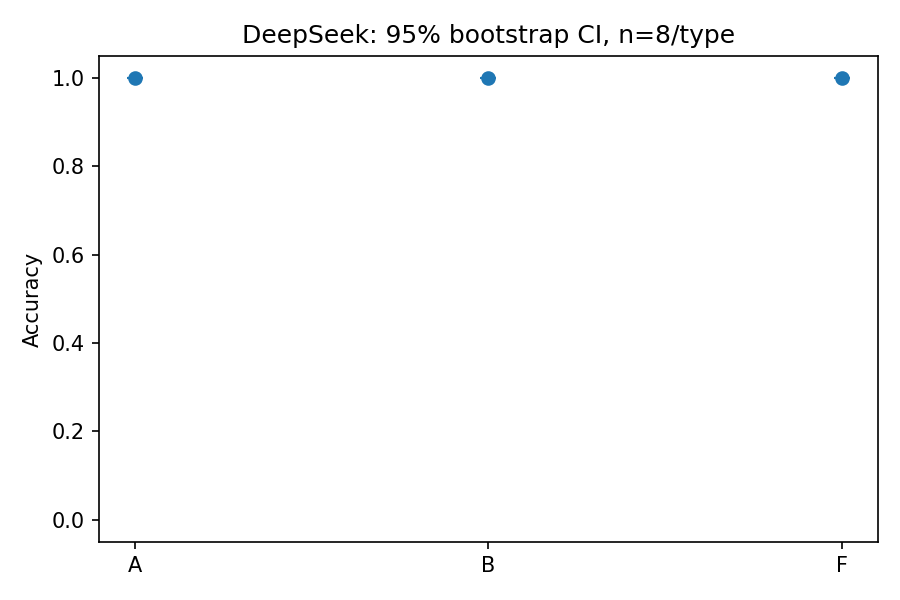

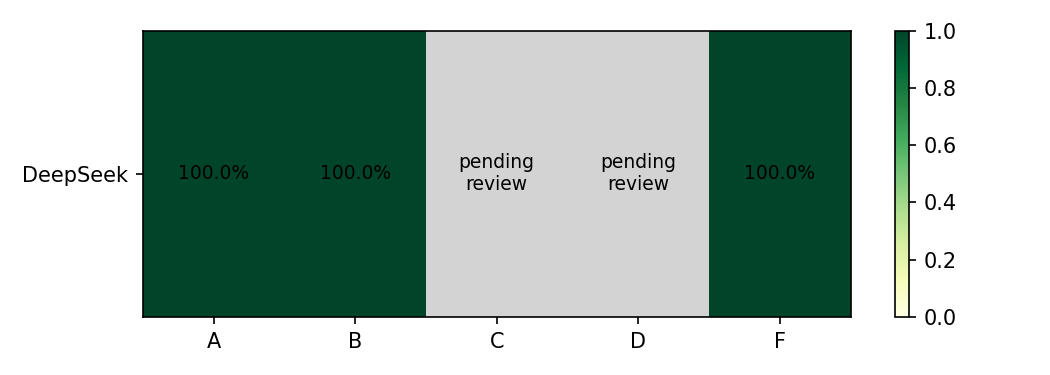

In [3]:
show_csv('type_metrics.csv')
show_csv('automatic_scores.csv')
figure('accuracy_ci.png')
figure('heatmap.png')
for prefix in 'ABF': show_answers(prefix,collapsed=True)

## E: классификация с 0, 5 и 20 примерами

В каждом из трёх режимов ровно 100 общих тестовых строк. Метка 1 — malignant, 0 — benign. Это обратная кодировка относительно исходного sklearn и D08. Используются те же шесть признаков, train5/train20 и test, что у остальных участников. LogisticRegression и GaussianNB обучены на тех же 5 и 20 примерах; у них нет режима без обучения.

Незавершённый ответ, отказ и невалидный формат обозначены −1 и считаются неуспехом для истинного класса. Они не превращаются в класс 0. Coverage — доля допустимых предсказаний, а не доля полученных HTTP-ответов. Основная метрика — F1 класса 1, дополнительная — balanced accuracy; константа предсказывает частый класс. Интервалы условны на один фиксированный набор демонстраций каждого размера.

model,shots,f1_minority,balanced_accuracy,accuracy,coverage,abstentions,incomplete_responses
DeepSeek,0,0.8064516129032258,0.7346632346632347,0.75,0.76,24,24
DeepSeek,5,0.7352941176470589,0.49656799656799655,0.45,0.51,49,49
DeepSeek,20,0.6545454545454545,0.3781638781638782,0.35,0.35,65,65
LogisticRegression,5,0.8043478260869565,0.8571428571428572,0.82,1.0,0,0
LogisticRegression,20,0.9117647058823529,0.9189189189189189,0.94,1.0,0,0
GaussianNB,5,0.8043478260869565,0.8571428571428572,0.82,1.0,0,0
GaussianNB,20,0.8181818181818182,0.848991848991849,0.88,1.0,0,0
constant_majority,0,0.0,0.5,0.63,1.0,0,0


[
  {
    "model": "DeepSeek",
    "shots": 0,
    "f1_minority": 0.8064516129032258,
    "balanced_accuracy": 0.7346632346632347,
    "accuracy": 0.75,
    "coverage": 0.76,
    "abstentions": 24,
    "incomplete_responses": 24,
    "ci": {
      "f1_minority": [
        0.67795243302351,
        0.9014084507042254
      ],
      "balanced_accuracy": [
        0.6460877431026685,
        0.8218470083718752
      ],
      "accuracy": [
        0.67,
        0.83
      ]
    }
  },
  {
    "model": "DeepSeek",
    "shots": 5,
    "f1_minority": 0.7352941176470589,
    "balanced_accuracy": 0.49656799656799655,
    "accuracy": 0.45,
    "coverage": 0.51,
    "abstentions": 49,
    "incomplete_responses": 49,
    "ci": {
      "f1_minority": [
        0.6037586103623839,
        0.8405879446640315
      ],
      "balanced_accuracy": [
        0.4016158169409875,
        0.5926640926640927
      ],
      "accuracy": [
        0.36,
        0.5402499999999998
      ]
    }
  },
  {
    "mode

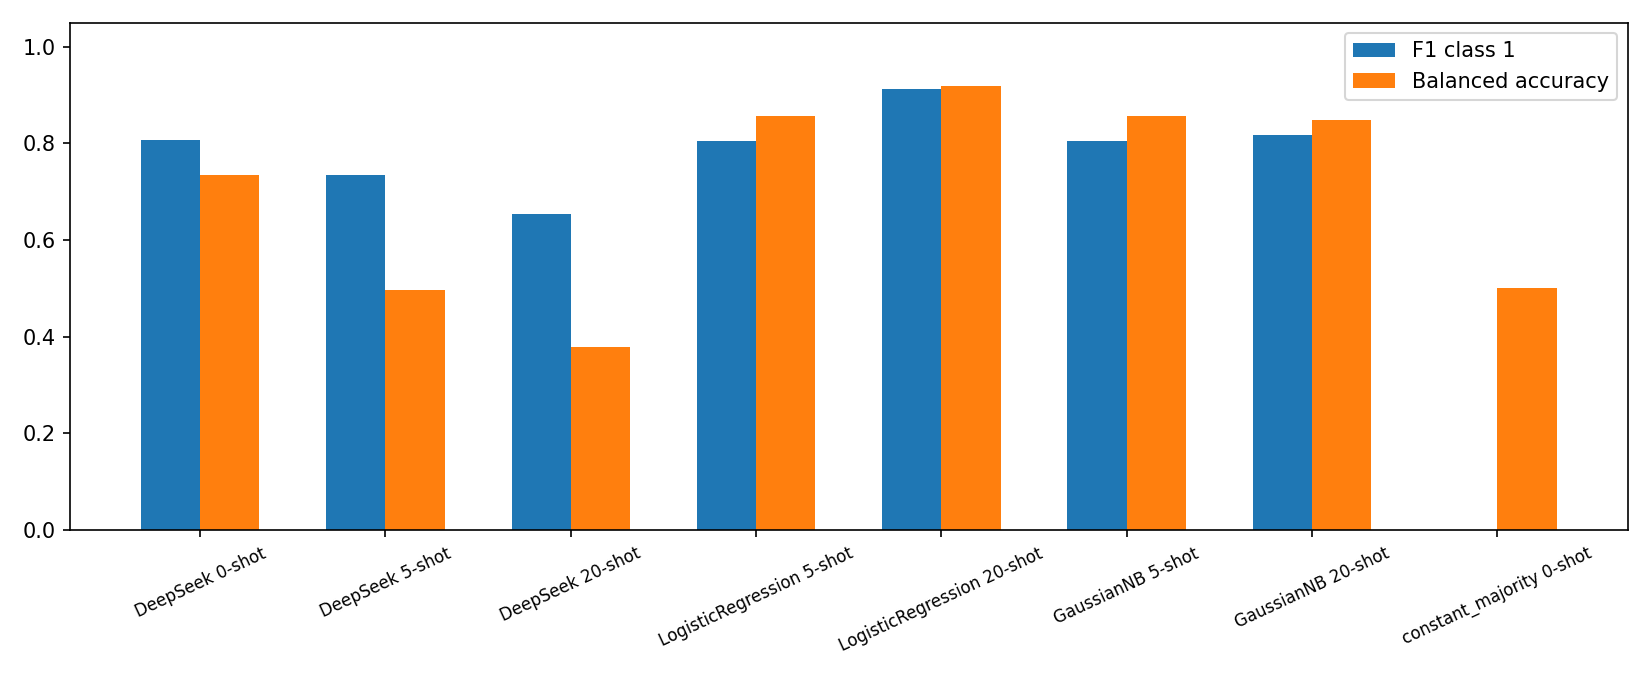

In [4]:
show_csv('classification_metrics.csv')
show_json('classification_metrics.json')
figure('classification.png')

## H10: калибровка уверенности

Используются заранее выбранные 24 задачи A/B/F. Проверяется средняя confidence/100 минус accuracy на валидных ответах; coverage и accuracy с полным знаменателем показаны отдельно. Кластерный bootstrap сохраняет связанные F-пары. ECE оценивает величину расхождения, но сам по себе не доказывает завышение уверенности. Проверка исследовательская; коррекция семейства гипотез не заявляется.

{
  "n_total": 24,
  "n_valid": 24,
  "coverage": 1.0,
  "mean_confidence": 0.9979166666666668,
  "accuracy_on_valid": 1.0,
  "full_denominator_accuracy": 1.0,
  "gap": -0.002083333333333335,
  "ci_low": -0.004090909090909095,
  "ci_high": -0.0007142857142857149,
  "ece": 0.002083333333333215,
  "decision": "reject",
  "bins": [
    {
      "bin_low": 0.0,
      "bin_high": 0.2,
      "n": 0,
      "mean_confidence": null,
      "accuracy": null
    },
    {
      "bin_low": 0.2,
      "bin_high": 0.4,
      "n": 0,
      "mean_confidence": null,
      "accuracy": null
    },
    {
      "bin_low": 0.4,
      "bin_high": 0.6,
      "n": 0,
      "mean_confidence": null,
      "accuracy": null
    },
    {
      "bin_low": 0.6,
      "bin_high": 0.8,
      "n": 0,
      "mean_confidence": null,
      "accuracy": null
    },
    {
      "bin_low": 0.8,
      "bin_high": 1.0,
      "n": 24,
      "mean_confidence": 0.9979166666666668,
      "accuracy": 1.0
    }
  ]
}


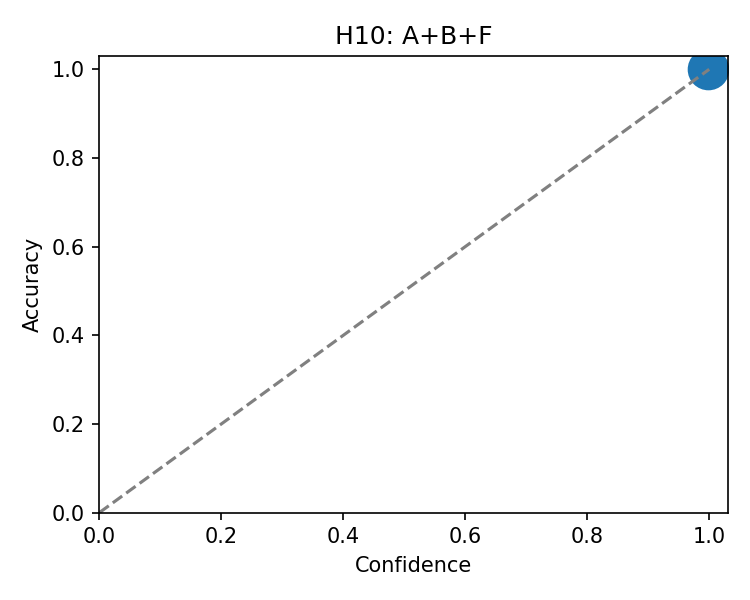

In [5]:
hypotheses=json.loads((OUT/'hypotheses.json').read_text(encoding='utf-8'))
print(json.dumps(hypotheses['H10'],ensure_ascii=False,indent=2))
figure('reliability.png')

## H12: полное сравнение с 5 и 20 примерами

Показаны delta F1 = F1 DeepSeek − F1 LogisticRegression и односторонние bootstrap-границы 95% для обоих размеров обучения. Допуск не меньшего качества при 5-shot — 0,05; при 20-shot проверяется ожидаемое отставание. H12 подтверждается только при поддержке обеих частей, опровергается при противоречии хотя бы одной, иначе данных недостаточно. Правила зафиксированы до основного прогона. Все 100 ответов каждого режима, включая незавершённые генерации, входят в знаменатель.

Первичная H5 сравнивает YandexGPT и Qwen3 4B и рассчитывается в командном анализе. DeepSeek не подменяет выбранную большую модель.

{
  "decision": "insufficient_data",
  "comparisons": [
    {
      "shots": 5,
      "delta_f1_llm_minus_lr": -0.06905370843989767,
      "one_sided_95_lower": -0.18104787459398397,
      "one_sided_95_upper": 0.032560667340748244,
      "decision": "insufficient_data"
    },
    {
      "shots": 20,
      "delta_f1_llm_minus_lr": -0.2572192513368984,
      "one_sided_95_lower": -0.37354115479115485,
      "one_sided_95_upper": -0.1569611291486291,
      "decision": "confirm"
    }
  ],
  "primary_metric": "F1 minority class 1; paired bootstrap, seed 42"
}


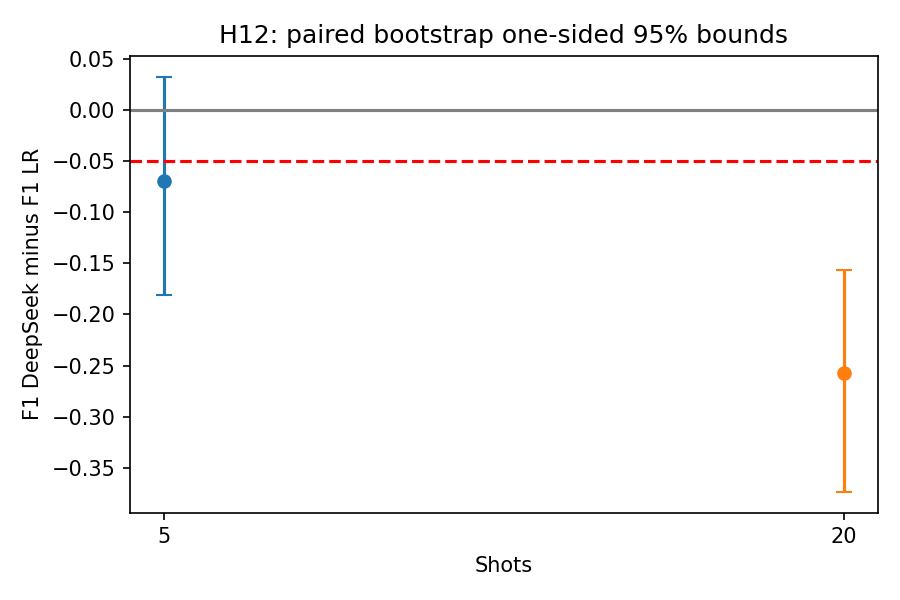

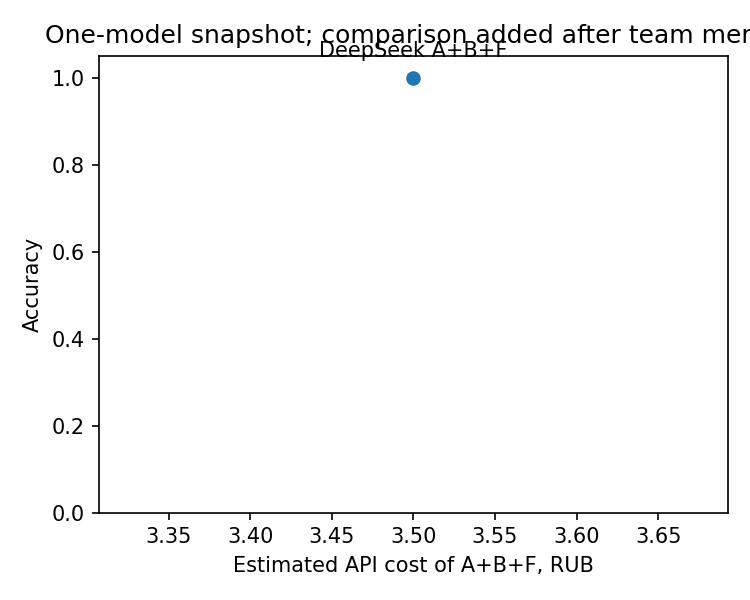

In [6]:
print(json.dumps(hypotheses['H12'],ensure_ascii=False,indent=2))
figure('h12_delta.png')
figure('cost_accuracy.png')

## C: выбор метода — все семь исходных ответов

Ответы отображаются без исправлений. Предложения модели могут быть неверными; публикация ответа не означает положительную оценку. Две независимые слепые оценки по рубрике ещё не заполнены.

In [7]:
show_answers('C')

## D: все восемь программ и результаты запуска

Код получен от DeepSeek, просмотрен перед исполнением и запущен без правок отдельно, без API-ключей, в каталоге выполнения, с ограничением времени и числом потоков. Это не полноценная ОС-песочница. При Run All программы повторно не исполняются. Отдельно показаны запускаемость, формат вывода и совпадение метрик с эталоном. Проверка методологии двумя независимыми участниками ещё требуется.

In [8]:
show_csv('code_metrics.csv')
show_answers('D')

task_id,source_sha256,exit_code,pass_at_1,output_is_json,metrics_match_reference,stderr_original_sha256,traceback_paths_normalized,methodology_review
D01,33c54ce905498c40e68ffee7295a619a56fe150bc0e3e2d9a2242049cc91bc0f,0,True,True,True,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855,True,pending_two_independent_reviewers
D02,4038a669eb299582380abf812078572712a8d26dafb30ea3973ce445f9ad846f,0,True,True,True,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855,True,pending_two_independent_reviewers
D03,f36a6a7273bd9c93d82b99283aba1bd2f1e9d4b98ceee22cc322e1e7e5693461,0,True,True,True,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855,True,pending_two_independent_reviewers
D04,ca29f9af6131c3d512bfef28b24bd572ed1f45b52b4e05855cbf32759fa878e2,0,True,True,True,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855,True,pending_two_independent_reviewers
D05,18da0bdc1602e5394cd056d98eac1e2e6248effe45a90867fe494945477c3872,0,True,True,True,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855,True,pending_two_independent_reviewers
D06,e3759f43cd0c56b892c8e1844fd327717018d21d4949c064c0a87deb0a8986ee,0,True,True,True,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855,True,pending_two_independent_reviewers
D07,955405cb26eee5937c48bf2d3abe989f2a1ef1578ca83dca5701ba6fb0a04e84,0,True,True,True,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855,True,pending_two_independent_reviewers
D08,018c1111fbb357c844c1072af8a1a677b7f79134b3a309e05c2bb8c92f86296c,0,True,True,True,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855,True,pending_two_independent_reviewers


## Независимая проверка и разбор случаев

Формы находятся в `analysis/deepseek/review/`. Организатор должен перемешать ответы разных моделей; пакет одной модели сам по себе не обеспечивает слепую проверку. Ключ сопоставления проверяющим не передаётся. Оценки и kappa не выдумываются, пропуски остаются пустыми.

Ниже сохранены пять случаев для самостоятельного разбора: сначала автоматически неверные A/B/F, затем первые незавершённые ответы классификации. При отсутствии ошибок A/B/F показаны фактические случаи исчерпания токенов с исходными usage и статусом сервера; внутренние рассуждения модели не выдумываются. Поле student_analysis оставлено для участников. Ограничения: маленький банк, публичный датасет, один few-shot набор, различия режима рассуждений и провайдера, обрывы сети, лимит рассуждений и неполная ручная оценка.

In [9]:
show_json('review_status.json')
show_json('error_examples.json')
show_json('provenance.json')
show_json('environment.json')

{
  "B": {
    "n_required": 8,
    "n_paired_scores": 0,
    "kappa": null,
    "status": "pending"
  },
  "C": {
    "n_required": 7,
    "n_paired_scores": 0,
    "kappa": null,
    "status": "pending"
  },
  "D": {
    "n_required": 8,
    "n_paired_scores": 0,
    "flag_agreement": {
      "leakage": {
        "n": 0,
        "kappa": null,
        "agreement": null
      },
      "test_tuning": {
        "n": 0,
        "kappa": null,
        "agreement": null
      },
      "train_evaluation": {
        "n": 0,
        "kappa": null,
        "agreement": null
      },
      "wrong_metric": {
        "n": 0,
        "kappa": null,
        "agreement": null
      },
      "missing_stratification": {
        "n": 0,
        "kappa": null,
        "agreement": null
      },
      "missing_seed": {
        "n": 0,
        "kappa": null,
        "agreement": null
      }
    },
    "status": "pending"
  }
}
[
  {
    "task_id": "E01",
    "row_id": "bc_007",
    "shots": 0,
    "promp